In [9]:
import pandas as pd
import numpy as np


In [10]:
xlsx_path = r"C:\Users\SSC\Desktop\job_intel\data\raw\indian-job-market-dataset-2025.xlsx"
csv_path = r"C:\Users\SSC\Desktop\job_intel\data\raw\jobs_raw.csv"

In [11]:
print("Loading Excel file...")
df = pd.read_excel(xlsx_path)

df.to_csv(csv_path, index=False)
print("Saved as CSV Succesfully")

Loading Excel file...
Saved as CSV Succesfully


In [12]:
print("Dataset shape (Rows, columns):",df.shape)

Dataset shape (Rows, columns): (97929, 17)


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 97929 entries, 0 to 97928
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   title              97929 non-null  str    
 1   jobId              97929 non-null  int64  
 2   currency           97929 non-null  str    
 3   jobUploaded        97929 non-null  str    
 4   companyName        97925 non-null  str    
 5   tagsAndSkills      97358 non-null  str    
 6   experience         95824 non-null  str    
 7   salary             97929 non-null  str    
 8   location           97929 non-null  str    
 9   companyId          97929 non-null  int64  
 10  ReviewsCount       62677 non-null  float64
 11  AggregateRating    62677 non-null  float64
 12  jobDescription     97929 non-null  str    
 13  minimumSalary      97358 non-null  float64
 14  maximumSalary      97358 non-null  float64
 15  minimumExperience  97358 non-null  float64
 16  maximumExperience  97358 non-null

In [14]:
null_counts = df.isnull().sum()
null_pct = (df.isnull().sum()/len(df))*100


null_summary = pd.DataFrame({
    'Missing_count': null_counts,
    'Missing %': null_pct.round(2)
})

print(null_summary[null_summary['Missing_count'] >0])

                   Missing_count  Missing %
companyName                    4       0.00
tagsAndSkills                571       0.58
experience                  2105       2.15
ReviewsCount               35252      36.00
AggregateRating            35252      36.00
minimumSalary                571       0.58
maximumSalary                571       0.58
minimumExperience            571       0.58
maximumExperience            571       0.58


In [15]:
#Display all 17 columns without hiding any column in the middle

pd.set_option('display.max_columns', None)

# view the first 3 rows of the dataset

df.head(3)

,title,jobId,currency,jobUploaded,companyName,tagsAndSkills,experience,salary,location,companyId,ReviewsCount,AggregateRating,jobDescription,minimumSalary,maximumSalary,minimumExperience,maximumExperience
0,Sr. HR Recruiter (NON IT),270925008041,INR,6 Days Ago,Orion,"Communication,Manpower,Staffing,Convincing Pow...",2-4 Yrs,2-4 Lacs PA,Kolkata(Chinar Park),645563,NaN,NaN,Preferred candidate profile . .,200000.0,400000.0,2.0,4.0
1,Fire And Safety Officer,270925007584,INR,6 Days Ago,"Apollo Hospitals International Limited, Ahmedabad","Safety Officer Activities,Fire Protection,Fire...",6-11 Yrs,3-5 Lacs PA,"Gandhinagar, Ahmedabad",14072,5162.0,4.0,"Ensure active Fire Protection System,such as F...",300000.0,500000.0,6.0,11.0
2,Opening For Performance Marketing - Chennai,270925007492,INR,6 Days Ago,TVS Credit Services Ltd,"Performance Marketing,User Acquisition,growth ...",12-18 Yrs,Not disclosed,Chennai,1324750,2892.0,4.2,MBA Marketing (preferred Tier II or III B- Sch...,0.0,0.0,12.0,18.0


In [18]:
df.nunique()

title                55104
jobId                97679
currency                 2
jobUploaded             30
companyName          18668
tagsAndSkills        84307
experience             287
salary                1339
location             10066
companyId            18328
ReviewsCount          1375
AggregateRating         41
jobDescription       80679
minimumSalary          164
maximumSalary          204
minimumExperience       31
maximumExperience       33
dtype: int64

In [20]:
#check min max average and percentatiles of all numerical columns 

df[['minimumSalary','maximumSalary','minimumExperience','maximumExperience','AggregateRating','ReviewsCount']].describe().round(2)

,minimumSalary,maximumSalary,minimumExperience,maximumExperience,AggregateRating,ReviewsCount
count,97358.00,97358.00,97358.00,97358.00,62677.00,62677.00
mean,198309.20,318609.58,3.96,7.73,3.68,14662.59
std,564076.48,841733.62,3.58,4.50,0.48,24744.51
min,0.00,0.00,0.00,0.00,1.00,2.00
25%,0.00,0.00,1.00,5.00,3.50,65.00
50%,0.00,0.00,3.00,7.00,3.70,962.00
75%,200000.00,375000.00,5.00,10.00,3.90,12826.00
max,70000000.00,95000000.00,30.00,35.00,5.00,104449.00


In [21]:
print(df['currency'].value_counts(dropna=False))

print("\nJobs with disclosed salary (> 0)", (df['minimumSalary']>0).sum())

currency
INR    97800
USD      129
Name: count, dtype: int64

Jobs with disclosed salary (> 0) 33229


# PHASE 2


In [22]:
# KEEP ONLY inr currency rows

df = df[df['currency'] == 'INR'].copy()

# drop the 571 unscraped rows where core fields (like minimumExperience) are missing

df = df.dropna(subset=['minimumExperience','tagsAndSkills'])

print("Shape after removing USD and currupted rows:", df.shape)



Shape after removing USD and currupted rows: (97229, 17)


In [24]:
# Remove duplicates jobIDS

df = df.drop_duplicates(subset=['jobId'])

# remove reposted jobs with exacrt same title, company and description 
df = df.drop_duplicates(subset=['title','companyName','jobDescription'])

print("Shape after removingg all duplicates:", df.shape)


Shape after removingg all duplicates: (85613, 17)


In [25]:
# Replace 0.0 with  NaN in minimum and maximum salary columns

df['minimumSalary'] =  df['minimumSalary'].replace(0.0,pd.NA)
df['maximumSalary'] = df['maximumSalary'].replace(0.0,pd.NA)

#2 Check how many rows actually have a valid (non-NaN) salary now

print("Rows with valid disclosed Salary:", df['minimumSalary'].notnull().sum())
print("Rows with missing/not disclosed salary",df['minimumSalary'].isnull().sum())

Rows with valid disclosed Salary: 30024
Rows with missing/not disclosed salary 55589


In [26]:
import re

# Function to remove HTML tags from job description
def clean_html(text):
    if pd.isna(text):
        return ""
    # Regular expression to find and remove anything inside < >
    clean = re.sub('<.*?>', '', str(text))
    return clean.strip()

# Apply the cleaning function to jobDescription column
df['jobDescription'] = df['jobDescription'].apply(clean_html)

print("HTML tags cleaned successfully! Total rows in df:", len(df))

HTML tags cleaned successfully! Total rows in df: 85613


In [27]:
# --- DATA SANITY CHECK ---
print("1. Final Dataset Shape:", df.shape)
print("\n2. Missing Values Check in Core Columns:")
print(df[['jobId', 'title', 'companyName', 'minimumSalary']].isnull().sum())

print("\n3. Quick Preview (First 2 Rows):")
# display() shows a nice formatted table in Jupyter Notebook
display(df[['title', 'companyName', 'minimumSalary', 'minimumExperience']].head(2))

1. Final Dataset Shape: (85613, 17)

2. Missing Values Check in Core Columns:
jobId                0
title                0
companyName          4
minimumSalary    55589
dtype: int64

3. Quick Preview (First 2 Rows):


,title,companyName,minimumSalary,minimumExperience
0,Sr. HR Recruiter (NON IT),Orion,200000.0,2.0
1,Fire And Safety Officer,"Apollo Hospitals International Limited, Ahmedabad",300000.0,6.0


In [28]:
import os

# 1. Create the processed folder if it doesn't exist
os.makedirs('../data/processed', exist_ok=True)

# 2. Save the cleaned dataframe to CSV
output_path = '../data/processed/jobs_clean.csv'
df.to_csv(output_path, index=False)

print(f"Data successfully cleaned and saved to: {output_path}")
print("Final Clean Dataset Shape:", df.shape)

Data successfully cleaned and saved to: ../data/processed/jobs_clean.csv
Final Clean Dataset Shape: (85613, 17)


C:\Users\SSC\AppData\Local\Temp\ipykernel_11628\2200412831.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_titles.values,y=top_titles.index,palette='viridis')


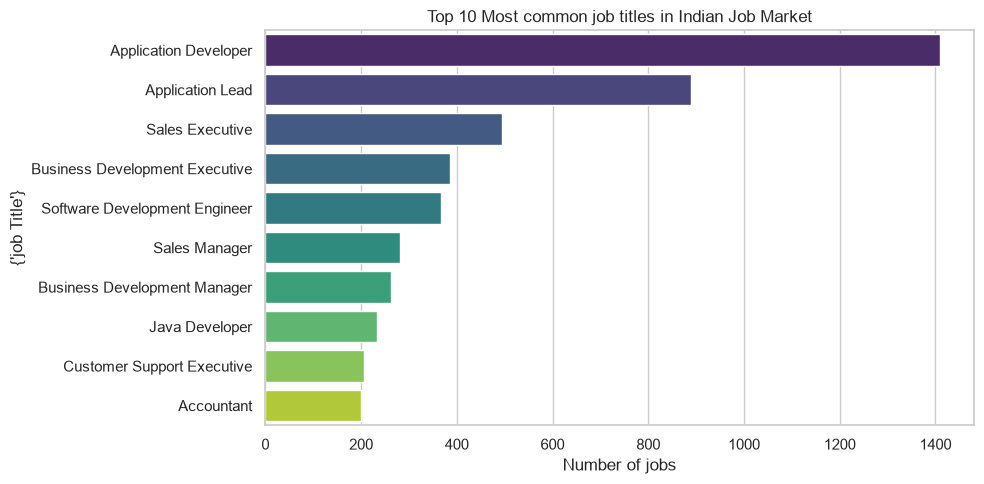

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# set style for nice charts
sns.set_theme(style='whitegrid')

# count top 10 job titles

top_titles = df['title'].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_titles.values,y=top_titles.index,palette='viridis')
plt.title("Top 10 Most common job titles in Indian Job Market")
plt.xlabel("Number of jobs")
plt.ylabel({"job Title"})
plt.tight_layout()
plt.show()


C:\Users\SSC\AppData\Local\Temp\ipykernel_11628\4268425283.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_locations.values,y=top_locations.index,palette="magma")


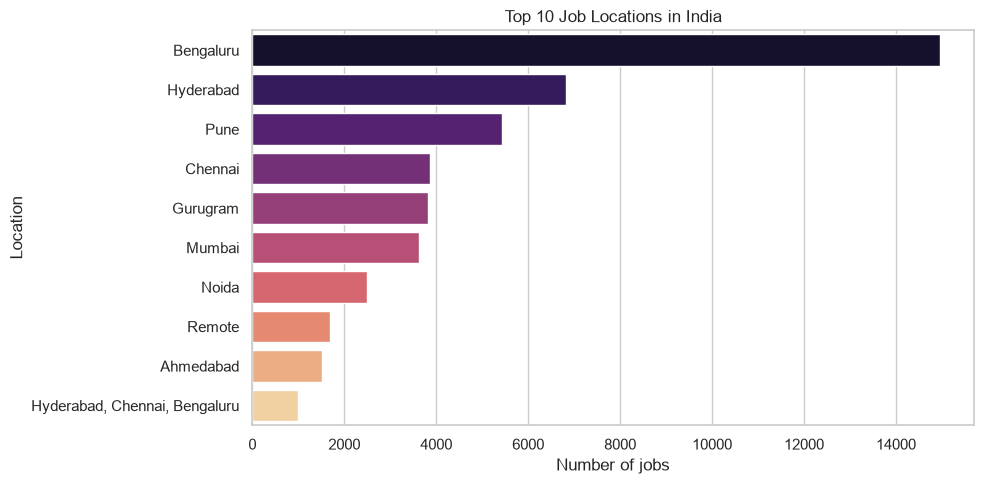

In [31]:
top_locations = df['location'].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_locations.values,y=top_locations.index,palette="magma")
plt.title("Top 10 Job Locations in India")
plt.xlabel("Number of jobs")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

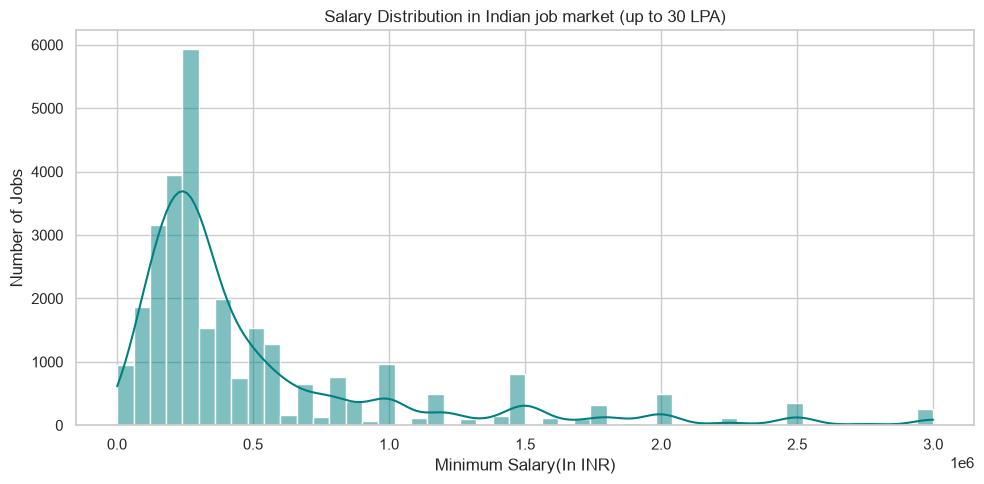

In [34]:
valid_salaries = df[df['minimumSalary'].notnull()]['minimumSalary']

plt.figure(figsize=(10,5))

# using hisplot to see salary ranges (limiting extreme ouliers up to 30 lakhs for clear view)

sns.histplot(valid_salaries[valid_salaries <= 3000000],bins = 50, kde=True, color="teal")
plt.title('Salary Distribution in Indian job market (up to 30 LPA)')
plt.xlabel("Minimum Salary(In INR)")
plt.ylabel("Number of Jobs")
plt.tight_layout()
plt.show()

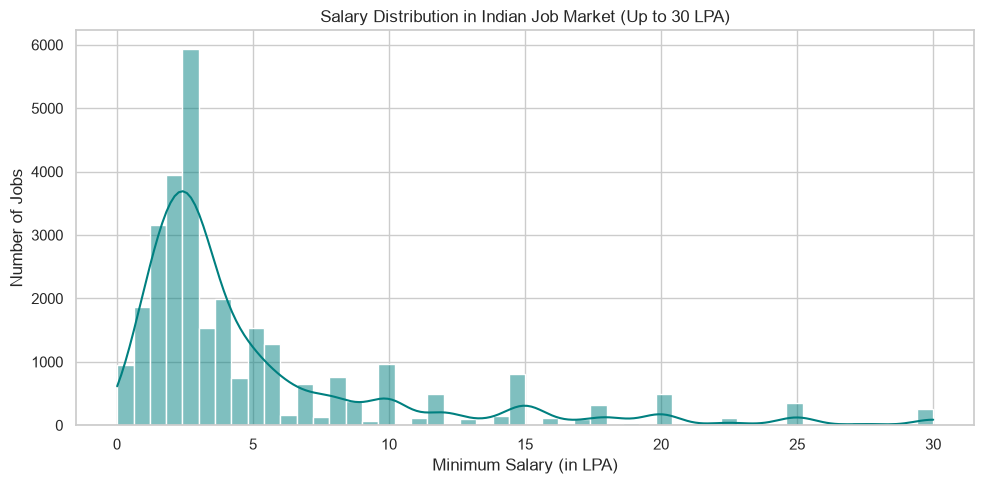

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter out NaN salaries and convert to LPA (Dividing by 100,000)
valid_salaries_lpa = df[df['minimumSalary'].notnull()]['minimumSalary'] / 100000

plt.figure(figsize=(10, 5))

# 2. Plotting up to 30 LPA for a clear view
sns.histplot(valid_salaries_lpa[valid_salaries_lpa <= 30], bins=50, kde=True, color="teal")

plt.title("Salary Distribution in Indian Job Market (Up to 30 LPA)")
plt.xlabel("Minimum Salary (in LPA)", fontsize=12)
plt.ylabel("Number of Jobs", fontsize=12)

plt.tight_layout()
plt.show()

C:\Users\SSC\AppData\Local\Temp\ipykernel_11628\2048413632.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='minimumExperience', y='minimumSalary_lpa', data=exp_sal_df[exp_sal_df['minimumExperience'] <= 10], palette="Set2")


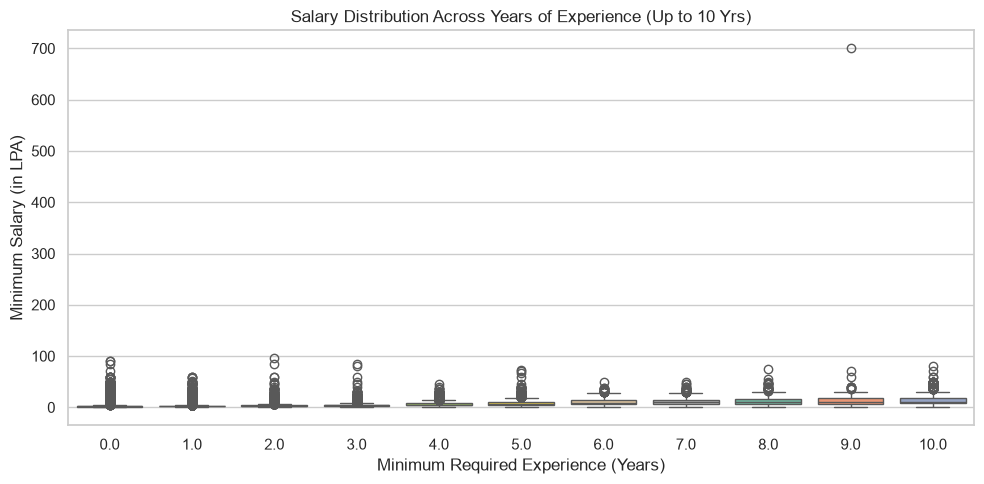

In [36]:
# Filter out rows where experience or salary is missing
exp_sal_df = df[df['minimumSalary'].notnull() & df['minimumExperience'].notnull()].copy()
exp_sal_df['minimumSalary_lpa'] = exp_sal_df['minimumSalary'] / 100000

plt.figure(figsize=(10, 5))
# Using boxplot to show salary spread across years of experience
sns.boxplot(x='minimumExperience', y='minimumSalary_lpa', data=exp_sal_df[exp_sal_df['minimumExperience'] <= 10], palette="Set2")
plt.title("Salary Distribution Across Years of Experience (Up to 10 Yrs)")
plt.xlabel("Minimum Required Experience (Years)", fontsize=12)
plt.ylabel("Minimum Salary (in LPA)", fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\SSC\AppData\Local\Temp\ipykernel_11628\3481880193.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_companies.values, y=top_companies.index, palette="crest")


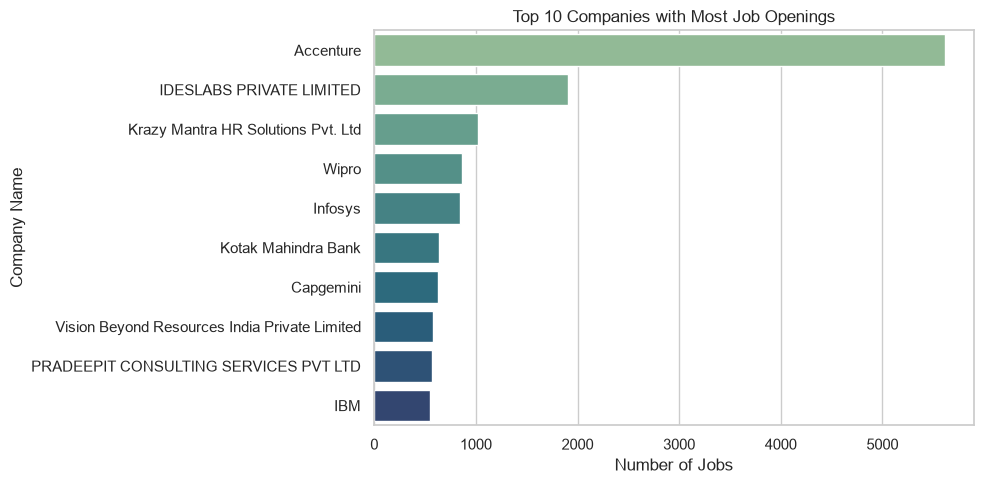

In [37]:
# Count top 10 companies posting jobs
top_companies = df['companyName'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_companies.values, y=top_companies.index, palette="crest")
plt.title("Top 10 Companies with Most Job Openings")
plt.xlabel("Number of Jobs", fontsize=12)
plt.ylabel("Company Name", fontsize=12)
plt.tight_layout()
plt.show()

In [38]:
import pandas as pd

# 1. Load the cleaned dataset
df = pd.read_csv('../data/processed/jobs_clean.csv')

print("==================================================")
print("       JOB MARKET EDA SUMMARY & KEY INSIGHTS      ")
print("==================================================")

# 2. Basic Dataset Info
print(f"Total Clean Job Postings: {len(df):,}")

# 3. Top 5 Job Titles
print("\n--- Top 5 Job Titles (Most Demand) ---")
top_titles = df['title'].value_counts().head(5)
for title, count in top_titles.items():
    print(f"• {title}: {count:,} jobs")

# 4. Top 5 Job Locations
print("\n--- Top 5 Job Locations (Tech Hubs) ---")
top_locs = df['location'].value_counts().head(5)
for loc, count in top_locs.items():
    print(f"• {loc}: {count:,} jobs")

# 5. Salary Insights (Converted to LPA)
valid_salaries = df['minimumSalary'].dropna() / 100000
print("\n--- Salary Insights (Minimum Salary in LPA) ---")
print(f"• Total Disclosed Salary Postings: {len(valid_salaries):,}")
print(f"• Median Salary: {valid_salaries.median():.2f} LPA")
print(f"• Average Salary: {valid_salaries.mean():.2f} LPA")
print(f"• Peak Range: Mostly concentrated between 3 to 5 LPA (Entry/Mid level)")

# 6. Top 5 Hiring Companies
print("\n--- Top 5 Hiring Companies ---")
top_comps = df['companyName'].value_counts().head(5)
for comp, count in top_comps.items():
    print(f"• {comp}: {count:,} jobs")

print("==================================================")

       JOB MARKET EDA SUMMARY & KEY INSIGHTS      
Total Clean Job Postings: 85,613

--- Top 5 Job Titles (Most Demand) ---
• Application Developer: 1,410 jobs
• Application Lead: 890 jobs
• Sales Executive: 495 jobs
• Business Development Executive: 386 jobs
• Software Development Engineer: 367 jobs

--- Top 5 Job Locations (Tech Hubs) ---
• Bengaluru: 14,949 jobs
• Hyderabad: 6,831 jobs
• Pune: 5,432 jobs
• Chennai: 3,872 jobs
• Gurugram: 3,810 jobs

--- Salary Insights (Minimum Salary in LPA) ---
• Total Disclosed Salary Postings: 30,024
• Median Salary: 3.00 LPA
• Average Salary: 5.84 LPA
• Peak Range: Mostly concentrated between 3 to 5 LPA (Entry/Mid level)

--- Top 5 Hiring Companies ---
• Accenture: 5,620 jobs
• IDESLABS PRIVATE LIMITED: 1,905 jobs
• Krazy Mantra HR Solutions Pvt. Ltd: 1,022 jobs
• Wipro: 866 jobs
• Infosys: 840 jobs
